# ORCHID tutorial 02: Kinetic Monte Carlo: mobility, TOF and relaxation

**Goals.** Run kinetic Monte Carlo for independent carriers (mobility, energy relaxation,
time of flight), and for interacting carriers with the $O(\log n)$ Fenwick-tree engine.

### Theory
KMC follows the BKL/Gillespie scheme. With total rate $R=\sum_k W_k$, the next event $k$ is chosen with
probability $W_k/R$ and the clock advances by $\Delta t=-\ln u/R$, where $u\in(0,1]$.
The mobility is $\mu = \langle x(t)\rangle/(F t)$. In a Gaussian DOS, a carrier at low density relaxes
to the equilibrium energy $\varepsilon_\infty=-\sigma^2/k_BT$ (Bässler 1993).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


In [2]:
from orchid.lattice import Lattice
from orchid.kmc import mobility_independent, mobility_interacting, energy_relaxation, time_of_flight
from orchid.constants import kB_eV
T = 300.0
for sh in (1.0, 2.0, 3.0):
    s = sh * kB_eV * T
    lat = Lattice(24, a=1.6e-9, seed=2).set_disorder(s)
    mu, err = mobility_independent(lat, T, 0.05 * s, n_carriers=64, n_eq=50000, n_meas=150000)
    print(f"sigma-hat={sh}: mu = {mu*1e4:.3e} +- {err*1e4:.1e} cm2/Vs")

sigma-hat=1.0: mu = 8.500e-10 +- 2.0e-11 cm2/Vs


sigma-hat=2.0: mu = 1.668e-10 +- 2.7e-12 cm2/Vs


sigma-hat=3.0: mu = 1.547e-11 +- 3.0e-13 cm2/Vs


Mobility falls steeply with disorder, roughly as $\ln\mu\approx -c\,\hat\sigma^2$. Next comes energy relaxation:

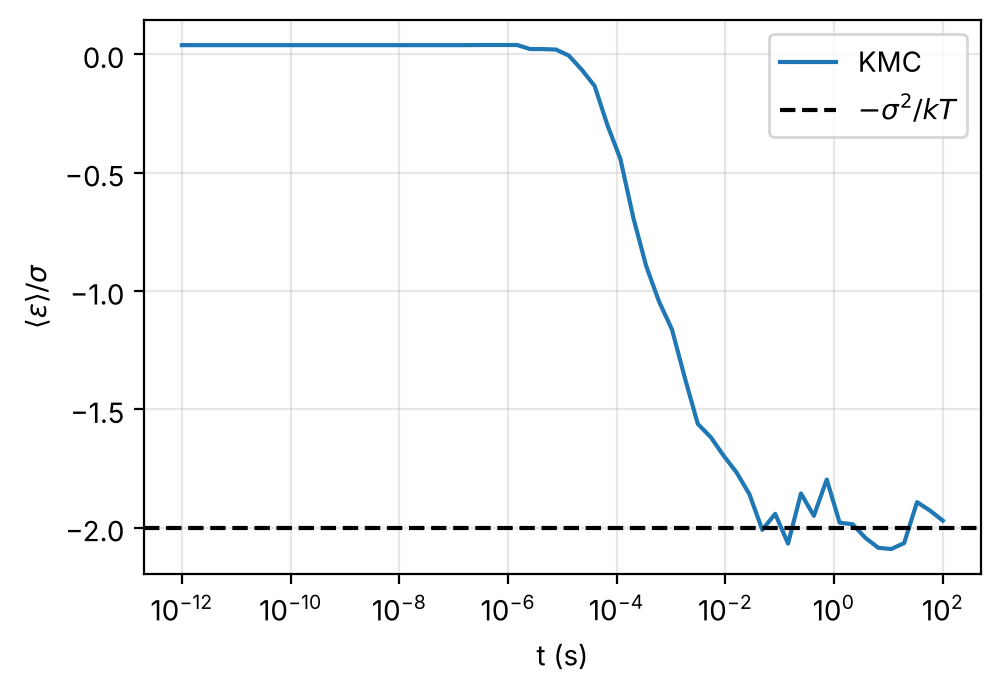

In [3]:
sh = 2.0; s = sh * kB_eV * T
lat = Lattice(30, a=1.6e-9, seed=3).set_disorder(s)
tg, E = energy_relaxation(lat, T, n_carriers=128, tgrid=np.logspace(-12, 2, 60))
plt.semilogx(tg, E / s, label="KMC")
plt.axhline(-sh, c="k", ls="--", label=r"$-\sigma^2/kT$")
plt.xlabel("t (s)"); plt.ylabel(r"$\langle\varepsilon\rangle/\sigma$"); plt.legend();

### Time of flight
Carriers start in a sheet and drift a distance $L$. The photocurrent $I(t)\propto d\langle x\rangle/dt$
is flat (non-dispersive) at low $\hat\sigma$. At high $\hat\sigma$ the plateau tilts and the tail broadens.

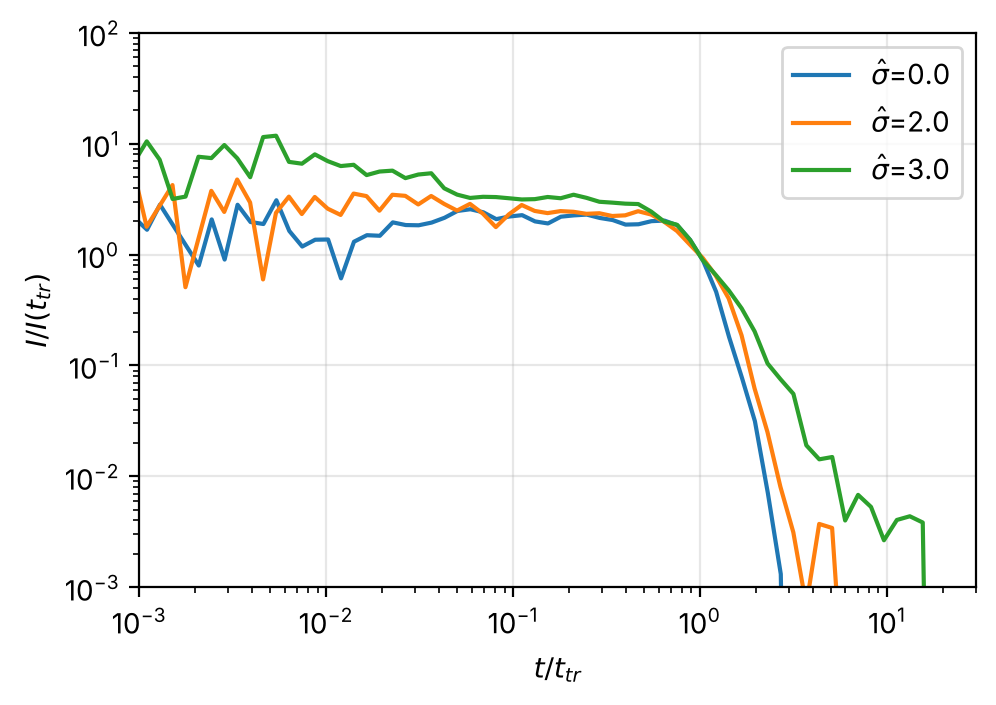

In [4]:
fig, ax = plt.subplots()
for sh in (0.0, 2.0, 3.0):
    s = max(sh * kB_eV * T, 1e-6)
    lat = Lattice(30, a=1.6e-9, seed=21).set_disorder(s)
    tg = np.logspace(-5, 6, 160)
    r = time_of_flight(lat, T, 0.4 * kB_eV * T, L_sample=60, n_carriers=256, tgrid=tg)
    I = r["I"]; m = I > 0
    ax.loglog(tg[m] / r["t_transit"], I[m] / np.interp(r["t_transit"], tg, I), label=rf"$\hat\sigma$={sh}")
ax.set_xlim(1e-3, 30); ax.set_ylim(1e-3, 1e2)
ax.set_xlabel(r"$t/t_{tr}$"); ax.set_ylabel(r"$I/I(t_{tr})$"); ax.legend();

### Interacting carriers
At finite density, site exclusion (and optionally Coulomb interaction) couples the carriers.
`mobility_interacting` uses a Fenwick tree for event selection and local rate updates, at $O(\log n)$ per event.

In [5]:
s = 3 * kB_eV * T
lat = Lattice(20, a=1.6e-9, seed=4).set_disorder(s)
for p in (1e-3, 1e-2, 3e-2):
    mu = mobility_interacting(lat, T, 0.05 * s, p, n_eq=50000, n_meas=200000)
    print(f"p = {p:.0e}: mu = {mu*1e4:.3e} cm2/Vs")

p = 1e-03: mu = 1.056e-11 cm2/Vs


p = 1e-02: mu = 3.778e-11 cm2/Vs


p = 3e-02: mu = 5.372e-11 cm2/Vs


**Exercise.** Why does mobility increase with carrier density in the cell above?

<details><summary>Solution</summary>

Deep tail states fill first, so the remaining carriers need less activation to reach the transport level. This is the EGDM $g_1(p)$ enhancement (tutorial 03).
</details>

**Exercise.** Repeat the energy relaxation at $\hat\sigma=3$. Why does the final value miss $-3\sigma$ on a 30³ lattice?

<details><summary>Solution</summary>

With $\hat\sigma=3$, the equilibrium energy lies $3\sigma$ deep, where a 27 000-site sample has very few states. The finite sample cannot represent the equilibrium tail (V4 calls this the finite-sample limit).
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("02", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 02`.

In [6]:
from orchid.tutorials import quiz
quiz("02")

Quiz 02: Kinetic Monte Carlo: mobility, TOF and relaxation

Q1. In the BKL/Gillespie algorithm, the time step after an event is drawn as
    (a) dt = u/R_tot
    (b) dt = -ln(u)/R_tot, u uniform in (0,1]
    (c) dt = 1/R_tot
    (d) dt = -ln(u)/W_chosen

Q2. What does the Fenwick tree in orchid._fenwick buy for interacting KMC with n events?
    (a) Exact parallelism
    (b) O(log n) selection and O(log n) update
    (c) O(1) selection, O(n) update
    (d) O(n) selection, O(1) update

Q3. At low density and long times, the mean energy of carriers in a Gaussian DOS of width sigma relaxes to
    (a) 0
    (b) -sigma^2/(2kT)
    (c) -sigma
    (d) -sigma^2/kT

Q4. A time-of-flight transient becomes dispersive when disorder increases. What do you see?
    (a) The plateau tilts and the post-transit tail broadens
    (b) A flat plateau and a sharp drop
    (c) The current increases after t_tr
    (d) No transit time can be defined

Q5. How is the drift mobility obtained from an independent-c

In [7]:
# replace with your answers, e.g. "abcda"
# quiz("02", answers=".....")

<details><summary>Answer key</summary>

`bbdab`. Run `quiz("02", answers="bbdab")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`